In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_path = project_dir / "data/processed/common_intake/common_records.csv"

In [2]:
common = pd.read_csv(output_path, dtype=str, keep_default_na=False)

### Repeated bill text

The shared preparation script has already removed repeated cleaned bill text.
Notebook 01 and the deduplication review document the four removed rows and
the records retained in the prepared table.
The check below confirms that the prepared table contains no repeated cleaned
bill text; applying the same keep-last rule removes no further rows.

In [3]:
duplicate_records = common.loc[
    common["Bill_Text_clean"].duplicated(keep=False), 
].sort_values("Bill_Text_clean")

# Compare bill identifiers, dates and outcomes.
columns_to_show = [
    "Bill_Title",
    "Bill_Number",
    "Jurisdiction",
    "NCSL_Category",
    "version_date_iso",
    "introduction_date_iso",
    "Bill_Status_Grouped",
    "Bill_Status"
]

display(duplicate_records[columns_to_show])

,Bill_Title,Bill_Number,Jurisdiction,NCSL_Category,version_date_iso,introduction_date_iso,Bill_Status_Grouped,Bill_Status


In [4]:
common.shape

(2567, 45)

In [5]:
main_bill_df = common.copy()
main_bill_df.shape

(2567, 45)

### Inspecting Target Variable Classes

In [6]:
summary = pd.crosstab(
    main_bill_df["introduction_date_iso"],
    main_bill_df["Bill_Status_Grouped"]
)

summary["Total"] = summary.sum(axis=1)
print(summary)

print(
    pd.crosstab(
        main_bill_df["introduction_date_iso"],
        main_bill_df["Bill_Status_Grouped"],
        normalize="index"
    ).round(3)
)

Bill_Status_Grouped    Failed  Passed  Pending  Total
introduction_date_iso                                
2018-12-03                  0       1        0      1
2019-01-08                  0       1        0      1
2019-01-10                  0       1        0      1
2019-01-16                  1       0        0      1
2019-01-18                  1       0        0      1
...                       ...     ...      ...    ...
2026-03-25                  1       0        2      3
2026-03-26                  0       0        1      1
2026-03-31                  0       0        5      5
2026-04-01                  0       0        1      1
2026-04-02                  0       0        1      1

[486 rows x 4 columns]
Bill_Status_Grouped    Failed  Passed  Pending
introduction_date_iso                         
2018-12-03              0.000     1.0    0.000
2019-01-08              0.000     1.0    0.000
2019-01-10              0.000     1.0    0.000
2019-01-16              1.000     0.0  

#### Review class distribution over time to define training cutoff

In [7]:
main_bill_df["introduction_date_iso"] = pd.to_datetime(main_bill_df["introduction_date_iso"], errors="coerce")

# Create month-year periods
main_bill_df["Intro_Month"] = main_bill_df["introduction_date_iso"].dt.to_period("M")
main_bill_df["Intro_Year"] = main_bill_df["introduction_date_iso"].dt.to_period("Y")

In [8]:
status_col = "Bill_Status_Grouped"

monthly_counts = pd.crosstab(main_bill_df["Intro_Month"], main_bill_df[status_col])

# Keep the same status order across plots.
desired_order = ["Failed", "Passed", "Pending"]
monthly_counts = monthly_counts.reindex(columns=desired_order, fill_value=0)

print(monthly_counts.head())

Bill_Status_Grouped  Failed  Passed  Pending
Intro_Month                                 
2018-12                   0       1        0
2019-01                   7       2        0
2019-02                  14       5        3
2019-03                   7       3        2
2019-04                   1       1        0


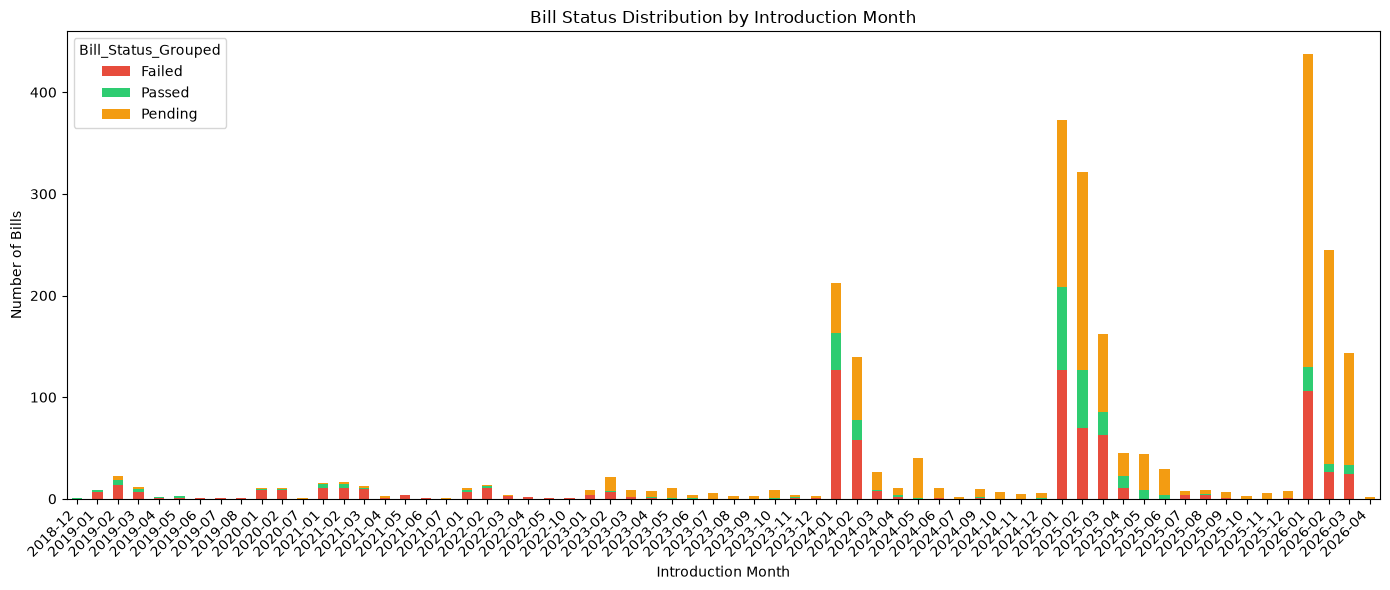

In [9]:
monthly_counts.index = monthly_counts.index.astype(str)

ax = monthly_counts.plot(
    kind="bar",
    stacked=True,
    color=['#e74c3c','#2ecc71', '#f39c12'],
    figsize=(14, 6)
)

ax.set_title("Bill Status Distribution by Introduction Month")
ax.set_xlabel("Introduction Month")
ax.set_ylabel("Number of Bills")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

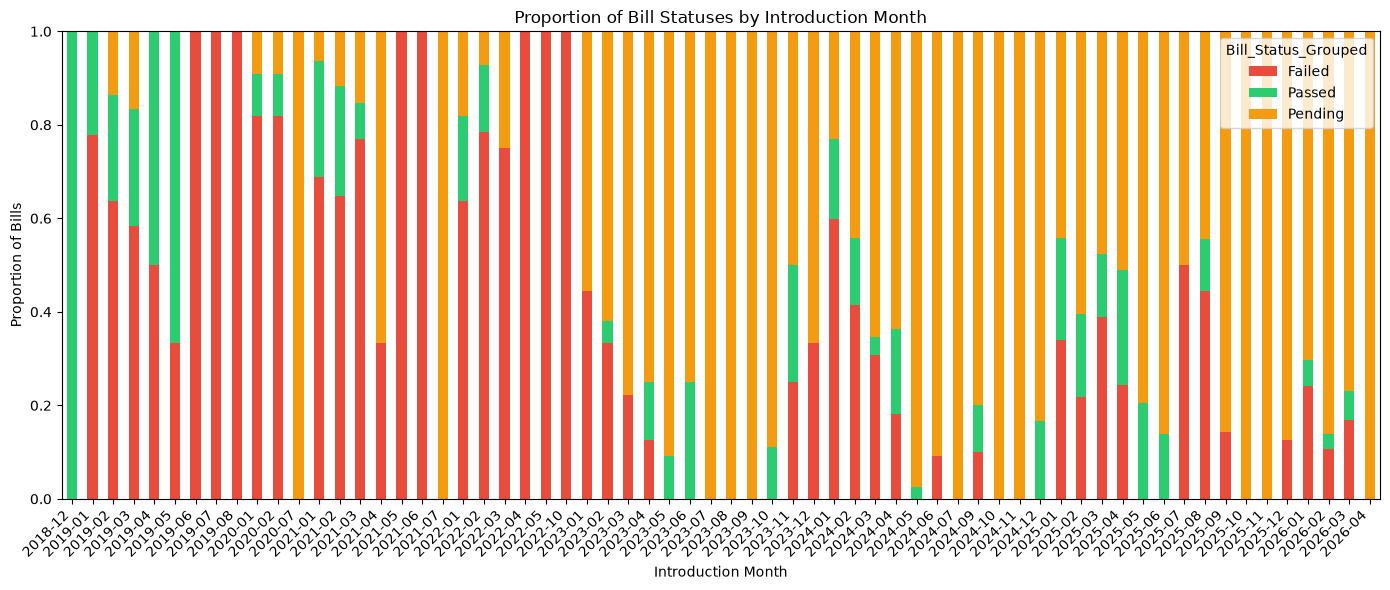

In [10]:
monthly_props = monthly_counts.div(monthly_counts.sum(axis=1), axis=0)

ax = monthly_props.plot(
    kind="bar",
    stacked=True,
    color=['#e74c3c','#2ecc71', '#f39c12'],
    figsize=(14, 6)
)

ax.set_title("Proportion of Bill Statuses by Introduction Month")
ax.set_xlabel("Introduction Month")
ax.set_ylabel("Proportion of Bills")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [11]:
yearly_counts = pd.crosstab(main_bill_df["Intro_Year"], main_bill_df[status_col])

# Keep the same status order across plots.
desired_order = ["Failed", "Passed", "Pending"]
yearly_counts = yearly_counts.reindex(columns=desired_order, fill_value=0)

print(yearly_counts)

Bill_Status_Grouped  Failed  Passed  Pending
Intro_Year                                  
2018                      0       1        0
2019                     33      13        5
2020                     18       2        3
2021                     38       9        8
2022                     25       4        4
2023                     16       6       68
2024                    197      62      211
2025                    281     185      550
2026                    156      41      631


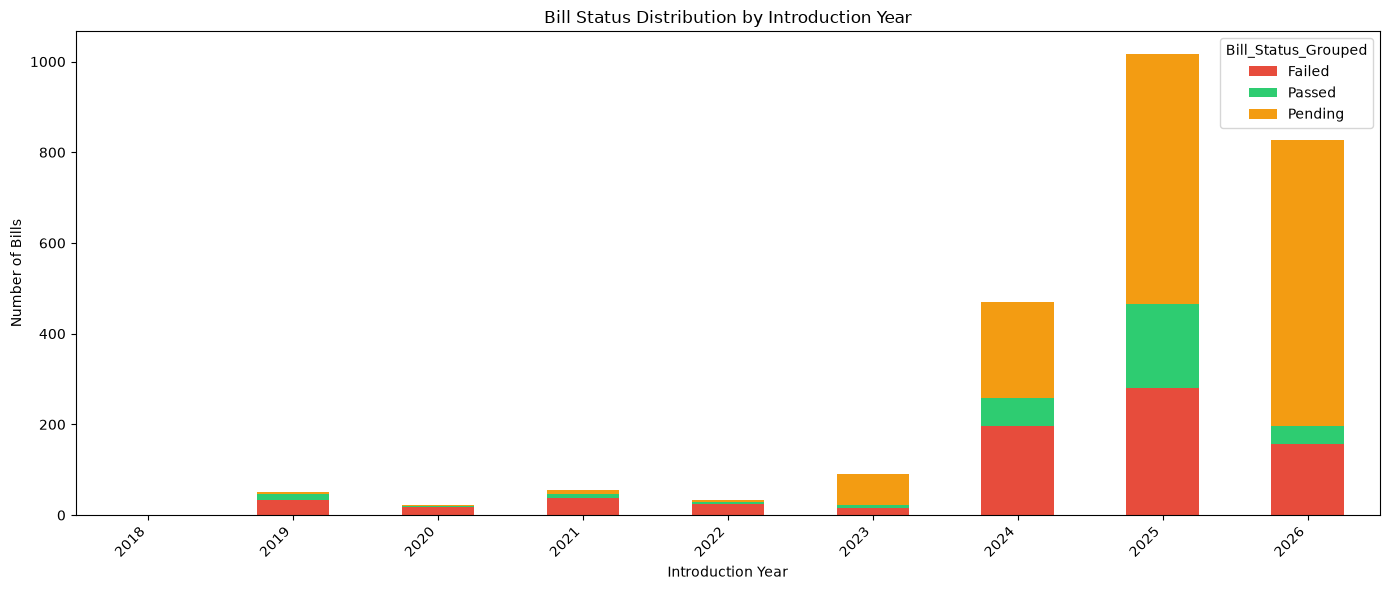

In [12]:
yearly_counts.index = yearly_counts.index.astype(str)

ax = yearly_counts.plot(
    kind="bar",
    stacked=True,
    color=['#e74c3c','#2ecc71', '#f39c12'],
    figsize=(14, 6)
)

ax.set_title("Bill Status Distribution by Introduction Year")
ax.set_xlabel("Introduction Year")
ax.set_ylabel("Number of Bills")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

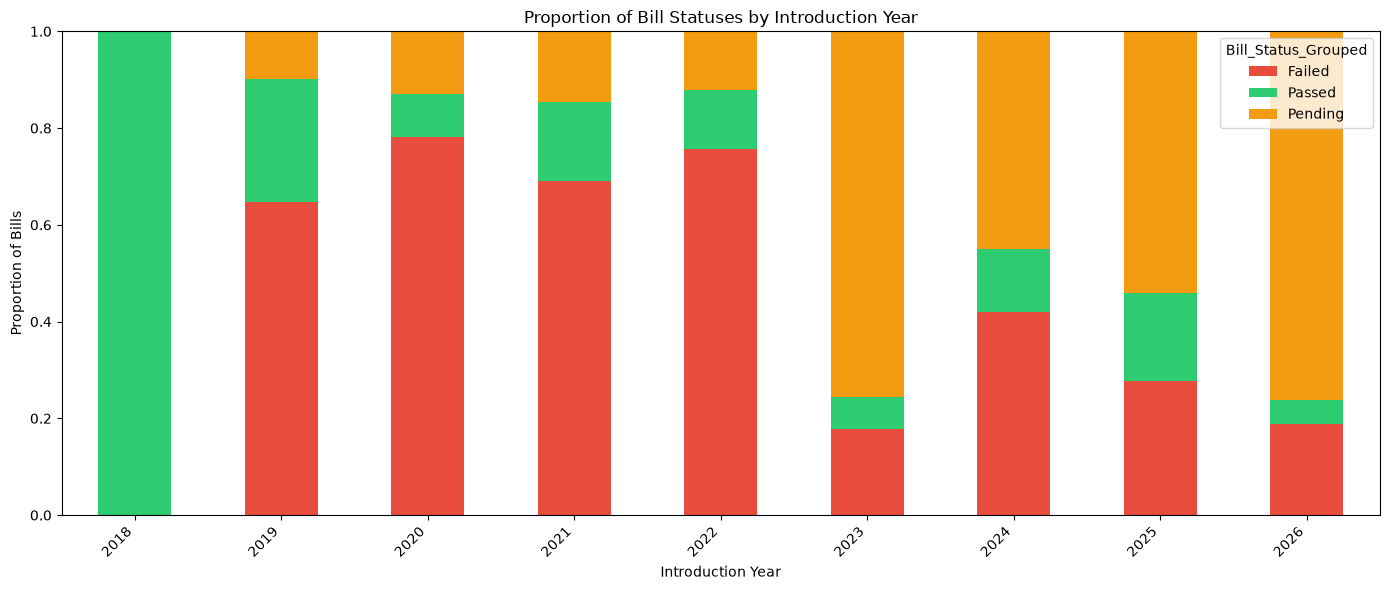

In [13]:
yearly_props = yearly_counts.div(yearly_counts.sum(axis=1), axis=0)

ax = yearly_props.plot(
    kind="bar",
    stacked=True,
    color=['#e74c3c','#2ecc71', '#f39c12'],
    figsize=(14, 6)
)

ax.set_title("Proportion of Bill Statuses by Introduction Year")
ax.set_xlabel("Introduction Year")
ax.set_ylabel("Proportion of Bills")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Second Check - All bills with intro = version dates, check distribution of classes and volume of bills

In [14]:
intro_version = main_bill_df.loc[(main_bill_df['introduction_date_iso'] == main_bill_df['version_date_iso'])]

In [15]:
print(intro_version["Bill_Status_Grouped"].value_counts(dropna=False))
print(intro_version["Bill_Status_Grouped"].value_counts(normalize=True))

Bill_Status_Grouped
Pending    1085
Failed      516
Passed        7
Name: count, dtype: int64
Bill_Status_Grouped
Pending    0.674751
Failed     0.320896
Passed     0.004353
Name: proportion, dtype: float64


In [16]:
monthly_counts2 = pd.crosstab(intro_version["Intro_Month"], intro_version[status_col])

# Keep the same status order across plots.
desired_order = ["Failed", "Passed", "Pending"]
monthly_counts2 = monthly_counts2.reindex(columns=desired_order, fill_value=0)

print(monthly_counts2.head())

Bill_Status_Grouped  Failed  Passed  Pending
Intro_Month                                 
2019-01                   4       0        0
2019-02                   7       0        0
2019-03                   5       0        1
2019-04                   1       0        0
2019-06                   1       0        0


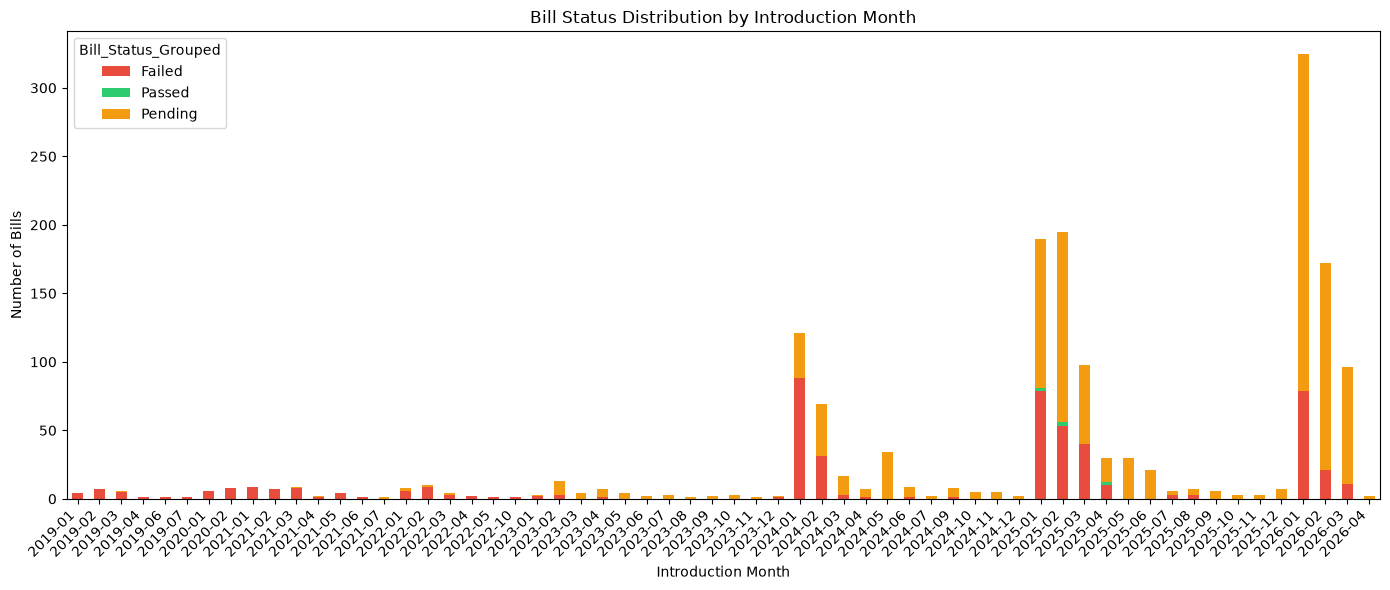

In [17]:
monthly_counts2.index = monthly_counts2.index.astype(str)

ax = monthly_counts2.plot(
    kind="bar",
    stacked=True,
    color=['#e74c3c','#2ecc71', '#f39c12'],
    figsize=(14, 6)
)

ax.set_title("Bill Status Distribution by Introduction Month")
ax.set_xlabel("Introduction Month")
ax.set_ylabel("Number of Bills")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

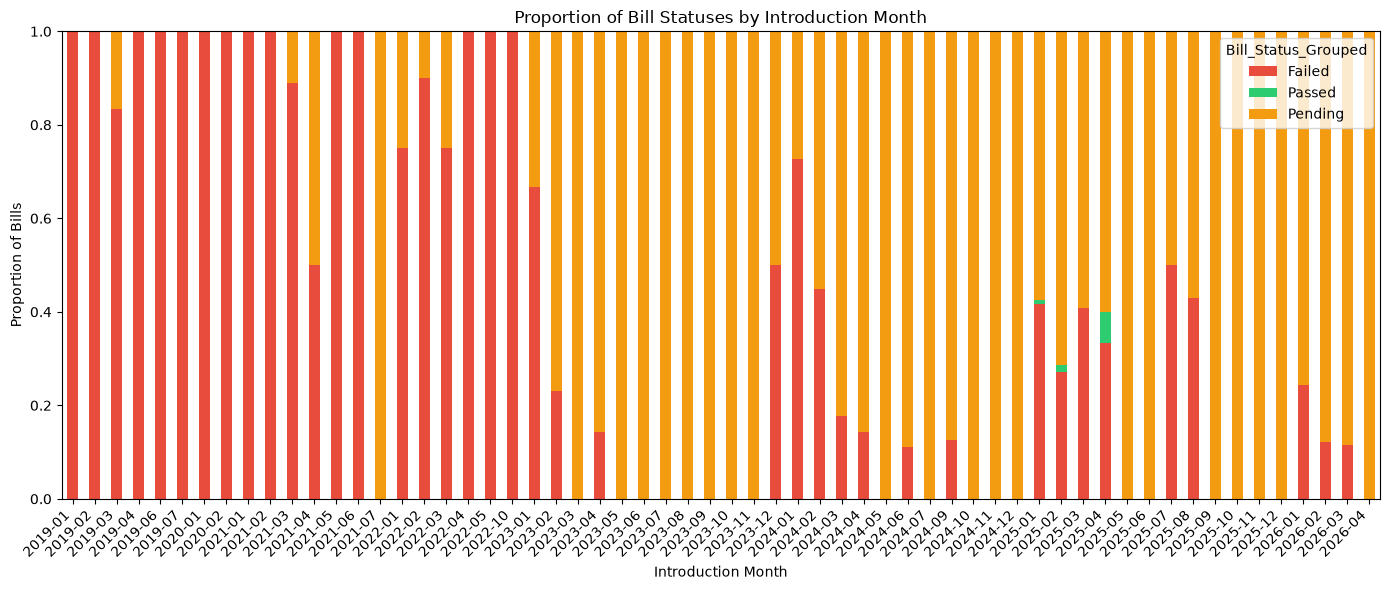

In [18]:
monthly_props2 = monthly_counts2.div(monthly_counts2.sum(axis=1), axis=0)

ax = monthly_props2.plot(
    kind="bar",
    stacked=True,
    color=['#e74c3c','#2ecc71', '#f39c12'],
    figsize=(14, 6)
)

ax.set_title("Proportion of Bill Statuses by Introduction Month")
ax.set_xlabel("Introduction Month")
ax.set_ylabel("Proportion of Bills")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Third Check - All bills with intro not = version dates, check distribution of classes and volume of bills

In [19]:
intro_not_version = main_bill_df.loc[(main_bill_df['introduction_date_iso'] != main_bill_df['version_date_iso'])]

In [20]:
print(intro_not_version["Bill_Status_Grouped"].value_counts(dropna=False))
print(intro_not_version["Bill_Status_Grouped"].value_counts(normalize=True))

Bill_Status_Grouped
Pending    395
Passed     316
Failed     248
Name: count, dtype: int64
Bill_Status_Grouped
Pending    0.411887
Passed     0.329510
Failed     0.258603
Name: proportion, dtype: float64


In [21]:
monthly_counts3 = pd.crosstab(intro_not_version["Intro_Month"], intro_not_version[status_col])

# Keep the same status order across plots.
desired_order = ["Failed", "Passed", "Pending"]
monthly_counts3 = monthly_counts3.reindex(columns=desired_order, fill_value=0)

print(monthly_counts3.head())

Bill_Status_Grouped  Failed  Passed  Pending
Intro_Month                                 
2018-12                   0       1        0
2019-01                   3       2        0
2019-02                   7       5        3
2019-03                   2       3        1
2019-04                   0       1        0


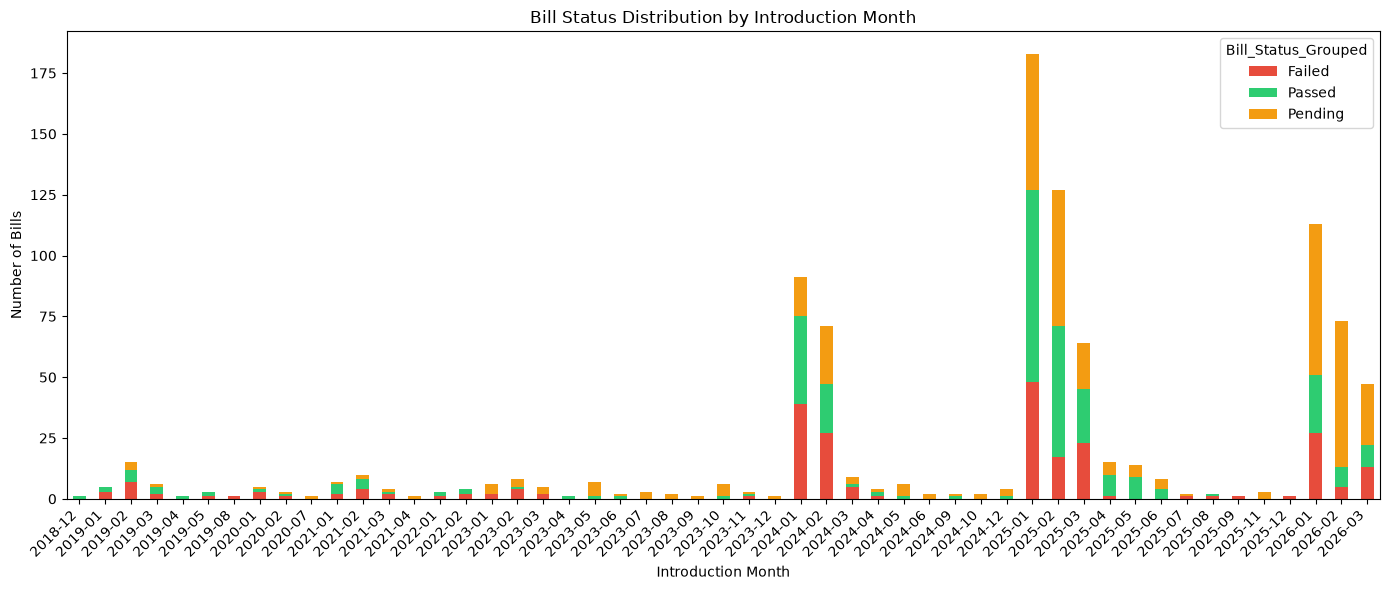

In [22]:
monthly_counts3.index = monthly_counts3.index.astype(str)

ax = monthly_counts3.plot(
    kind="bar",
    stacked=True,
    color=['#e74c3c','#2ecc71', '#f39c12'],
    figsize=(14, 6)
)

ax.set_title("Bill Status Distribution by Introduction Month")
ax.set_xlabel("Introduction Month")
ax.set_ylabel("Number of Bills")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

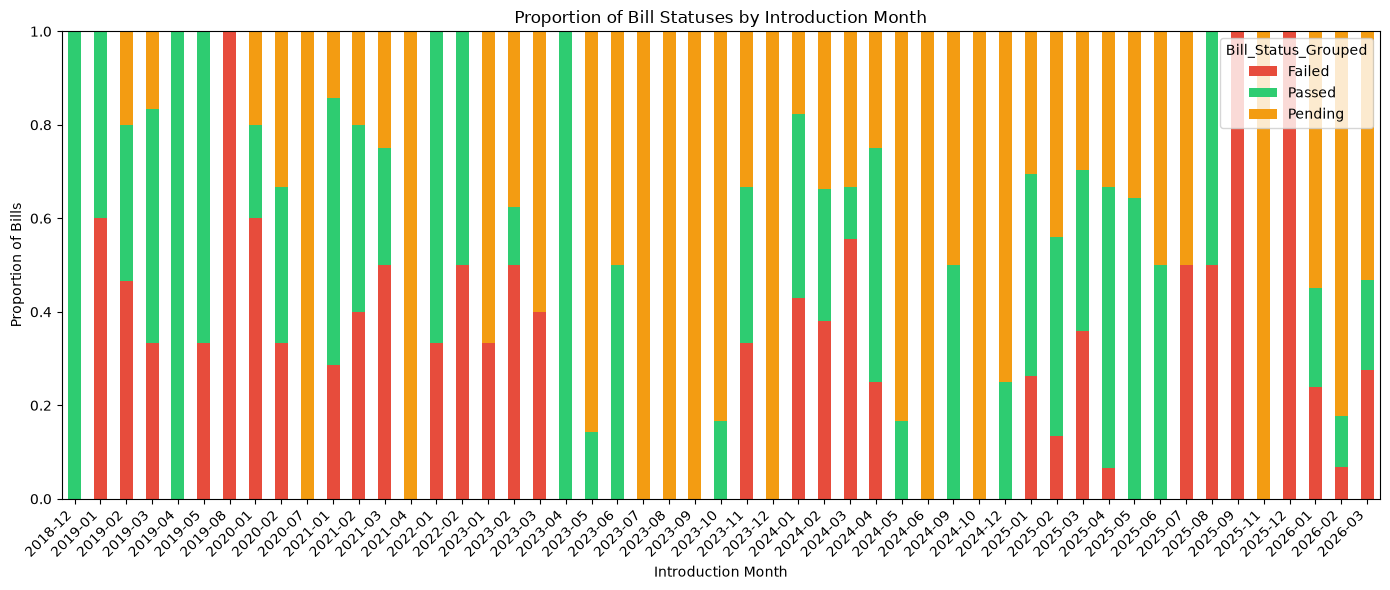

In [23]:
monthly_props3 = monthly_counts3.div(monthly_counts3.sum(axis=1), axis=0)

ax = monthly_props3.plot(
    kind="bar",
    stacked=True,
    color=['#e74c3c','#2ecc71', '#f39c12'],
    figsize=(14, 6)
)

ax.set_title("Proportion of Bill Statuses by Introduction Month")
ax.set_xlabel("Introduction Month")
ax.set_ylabel("Proportion of Bills")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Bills with different introduction and version dates have a higher recorded
pass rate in this snapshot. This association may reflect later-stage information
in the stored text; it does not show that version changes cause passage.
We therefore frame the task as retrospective classification of recorded outcomes.
Prediction at introduction would require historical text and metadata available
at that point.

### Supplemental features for possible consideration.

In [24]:
# Flag to indicate if the version date is different from the introduction date
main_bill_df["version_date_iso"] = pd.to_datetime(
    main_bill_df["version_date_iso"], errors="coerce"
)

main_bill_df["Version_Changed"] = (main_bill_df["version_date_iso"].dt.normalize() != main_bill_df["introduction_date_iso"].dt.normalize())

A view into the changes in status when version changes

In [25]:
distribution = pd.crosstab(
    index=[
        main_bill_df["Intro_Year"],
        main_bill_df["Version_Changed"]
    ],
    columns=main_bill_df["Bill_Status_Grouped"]
)

print(distribution)

Bill_Status_Grouped         Failed  Passed  Pending
Intro_Year Version_Changed                         
2018       True                  0       1        0
2019       False                19       0        1
           True                 14      13        4
2020       False                14       0        0
           True                  4       2        3
2021       False                30       0        3
           True                  8       9        5
2022       False                22       0        4
           True                  3       4        0
2023       False                 7       0       38
           True                  9       6       30
2024       False               125       0      154
           True                 72      62       57
2025       False               188       7      401
           True                 93     178      149
2026       False               111       0      484
           True                 45      41      147


### Review distribution of classes in target variable per following split:

Train: 2019 - 2024 <br/>
Validate: 2025 <br/>
Test: 2026 <br/>

In [26]:
year = main_bill_df["Intro_Year"].dt.year  

train = main_bill_df[year.between(2019, 2024)].copy()
val = main_bill_df[year == 2025].copy()
test = main_bill_df[year == 2026].copy()

for name, subset in [ 
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(f"\n{name}: {len(subset)} bills")

    print(
        subset["Bill_Status_Grouped"]
        .value_counts(normalize=True)
        .mul(100)
        .round(1)
    )


Train: 722 bills
Bill_Status_Grouped
Failed     45.3
Pending    41.4
Passed     13.3
Name: proportion, dtype: float64

Validation: 1016 bills
Bill_Status_Grouped
Pending    54.1
Failed     27.7
Passed     18.2
Name: proportion, dtype: float64

Test: 828 bills
Bill_Status_Grouped
Pending    76.2
Failed     18.8
Passed      5.0
Name: proportion, dtype: float64


We will use this split to create baseline models. 
Special consideration must be given to test set, as being the newer bills of the current year, it also carries a large amount of bills in pending status which could represent many bills not yet on a final outcome primarily because not all legislative sessions in the year have concluded. 